# LATENT ANALYSIS

## Corner Plot of PCA components and latents 

In [1]:
import sys
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import corner

In [2]:
sys.path.append('/home/gandalf/objects')
from train_vae import BetaTCVAE

In [3]:

checkpoint_path = '/home/gandalf/objects/betatcvae_dim12_beta5.pth'
data_path = '/home/gandalf/objects/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
subsample_size = 10000 
batch_size = 256


In [4]:
print(f"Loading checkpoint from {checkpoint_path}...")
checkpoint = torch.load(checkpoint_path, map_location=device)
checkpoint_args = checkpoint.get('args', {})
latent_dim = checkpoint_args.get('latent_dim', 10)

Loading checkpoint from /home/gandalf/objects/betatcvae_dim12_beta5.pth...


In [5]:

model = BetaTCVAE(latent_dim=latent_dim).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Model loaded successfully. Latent dimension (k) = {latent_dim}")


Model loaded successfully. Latent dimension (k) = 12


In [6]:
print(f"Loading dSprites dataset from {data_path}...")
data = np.load(data_path, allow_pickle=True, encoding='bytes')
imgs = data['imgs']


Loading dSprites dataset from /home/gandalf/objects/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz...


In [7]:
np.random.seed(42)
indices = np.random.choice(len(imgs), subsample_size, replace=False)
imgs_sub = imgs[indices]

In [8]:
mu_list = []
print("Encoding images into latent representations (mu)...")
with torch.no_grad():
    for i in range(0, len(imgs_sub), batch_size):
        batch_imgs = imgs_sub[i:i+batch_size]
        batch_tensor = torch.from_numpy(batch_imgs).float().unsqueeze(1).to(device)
        mu, _ = model.encode(batch_tensor)
        mu_list.append(mu.cpu().numpy())

mu_np = np.concatenate(mu_list, axis=0)
print(f"Extracted latents shape: {mu_np.shape}")


Encoding images into latent representations (mu)...
Extracted latents shape: (10000, 12)


In [9]:
scaler=StandardScaler()
mu_np = scaler.fit_transform(mu_np)

In [10]:
k = mu_np.shape[1] 
n = 6     

assert n <= k, f"Target dimension n={n} cannot be larger than the latent space dimension k={k}"

if n == k:
    obtained_space = mu_np
    labels = [f"$z_{{{i}}}$" for i in range(k)]
    title = f"Corner Plot of Actual Latent Space (dim = {k})"
    print(f"n == k ({n} == {k}): Using the actual latent space.")
else:
    print(f"n != k ({n} != {k}): Applying PCA to reduce to {n} dimensions...")
    pca = PCA(n_components=n)
    obtained_space = pca.fit_transform(mu_np)
    labels = [f"PCA Comp {i+1}" for i in range(n)]
    title = f"Corner Plot of PCA-Reduced Latent Space (n = {n} components)"


n != k (6 != 12): Applying PCA to reduce to 6 dimensions...


Generating corner plot...


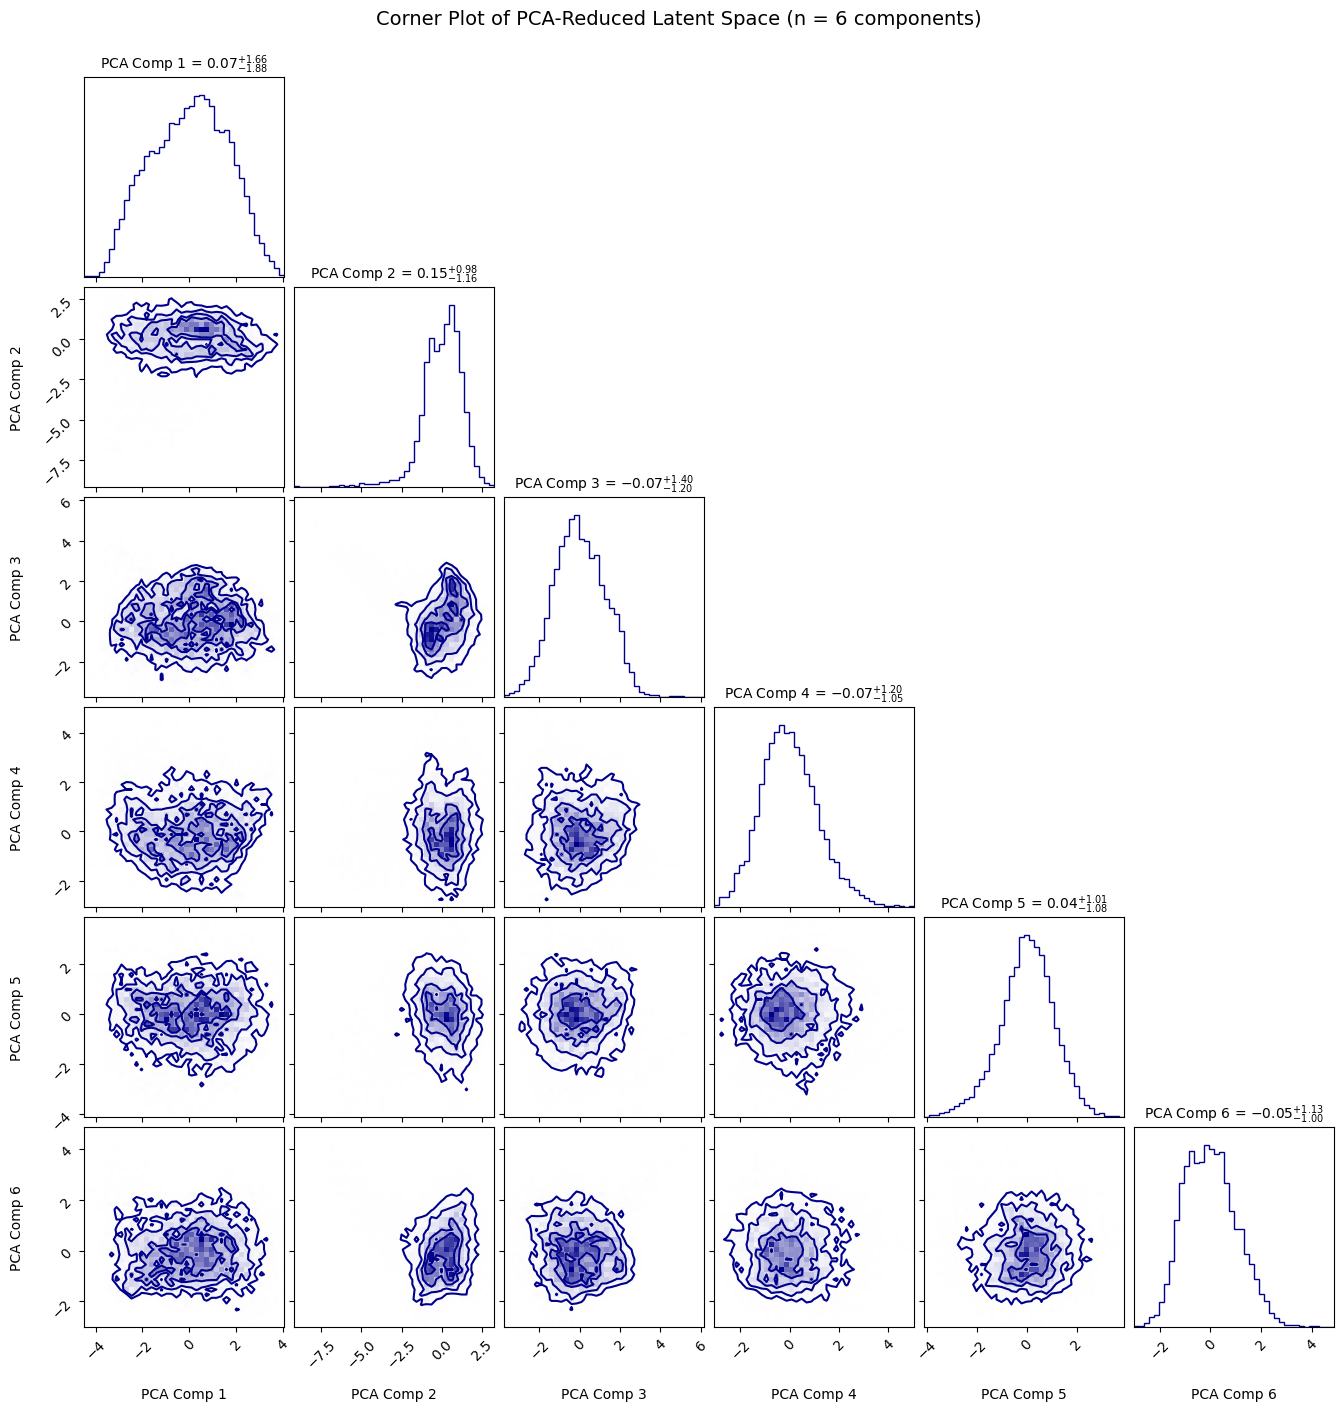

In [11]:
print("Generating corner plot...")
fig = corner.corner(
    obtained_space,
    labels=labels,
    show_titles=True,
    title_fmt=".2f",
    title_kwargs={"fontsize": 10},
    bins=40,
    plot_datapoints=False, 
    plot_density=True,
    fill_contours=False,
    color="darkblue",
    levels=[0.25,0.5,0.75,0.9]
)
fig.suptitle(title, y=1.02, fontsize=14)
plt.show()

## Regression Analysis

In [20]:
import sys
import os
import torch
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
sys.path.append('/home/gandalf/objects')
from train_vae import BetaTCVAE

checkpoint_path = '/home/gandalf/objects/betatcvae_dim12_beta5.pth'
data_path = '/home/gandalf/objects/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
subsample_size = 10000
batch_size = 256


In [11]:
use_pca = True       
n_components = 6


In [12]:
print(f"Loading checkpoint from {checkpoint_path}...")
checkpoint = torch.load(checkpoint_path, map_location=device)
checkpoint_args = checkpoint.get('args', {})
latent_dim = checkpoint_args.get('latent_dim', 12)

model = BetaTCVAE(latent_dim=latent_dim).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Model loaded. Latent dimension (k) = {latent_dim}")


Loading checkpoint from /home/gandalf/objects/betatcvae_dim12_beta5.pth...
Model loaded. Latent dimension (k) = 12


In [13]:
torch.cuda.empty_cache()

In [14]:
print("Loading dataset...")
data = np.load(data_path, allow_pickle=True, encoding='bytes')
imgs = data['imgs']
latents_classes = data['latents_classes']


Loading dataset...


In [15]:
np.random.seed(42)
indices = np.random.choice(len(imgs), subsample_size, replace=False)
imgs_sub = imgs[indices]
latents_sub = latents_classes[indices]

shape_labels = latents_sub[:, 1]                             
scale_labels = (latents_sub[:, 2] >= 3).astype(np.int64)     
position_labels = (latents_sub[:, 4] >= 16).astype(np.int64) 

In [16]:

mu_list = []
print("Encoding images into latent representations...")
with torch.no_grad():
    for i in range(0, len(imgs_sub), batch_size):
        batch_imgs = imgs_sub[i:i+batch_size]
        batch_tensor = torch.from_numpy(batch_imgs).float().unsqueeze(1).to(device)
        mu, _ = model.encode(batch_tensor)
        mu_list.append(mu.cpu().numpy())

mu_np = np.concatenate(mu_list, axis=0)


Encoding images into latent representations...


In [17]:
if use_pca:
    scaler1= StandardScaler()
    mu_nps= scaler1.fit_transform(mu_np)
    print(f"Applying PCA (n_components={n_components}) on the latent space...")
    pca = PCA(n_components=n_components)
    X_features = pca.fit_transform(mu_np)
    feature_names = [f"PCA_Comp_{i+1}" for i in range(n_components)]
else:
    print("Using the actual 12D latent space directly...")
    X_features = mu_np
    feature_names = [f"z_{i}" for i in range(latent_dim)]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)


Applying PCA (n_components=6) on the latent space...


In [21]:
targets = {
    "Shape": shape_labels,
    "Scale": scale_labels,
    "Position": position_labels
}

importance_df = pd.DataFrame({"Feature": feature_names})
performance_records = []

for name, y in targets.items():
    print(f"Evaluating models for target: {name}...")
    
    lr = LinearRegression()
    lr.fit(X_scaled, y)
    y_pred_lr = lr.predict(X_scaled)
    
    r2_lr = r2_score(y, y_pred_lr)
    y_pred_lr_rounded = np.clip(np.round(y_pred_lr), y.min(), y.max()).astype(int)
    acc_lr = accuracy_score(y, y_pred_lr_rounded)
    lr_importance = np.abs(lr.coef_)
    
    rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    rf.fit(X_features, y)
    y_pred_rf = rf.predict(X_features)
    
    r2_rf = r2_score(y, y_pred_rf)
    y_pred_rf_rounded = np.clip(np.round(y_pred_rf), y.min(), y.max()).astype(int)
    acc_rf = accuracy_score(y, y_pred_rf_rounded)
    rf_importance = rf.feature_importances_

    importance_df[f"{name} (Linear Reg Coef)"] = lr_importance
    importance_df[f"{name} (Random Forest Imp)"] = rf_importance
    performance_records.append({
        "Attribute": name,
        "Linear Reg R2": r2_lr,
        "Linear Reg Accuracy": acc_lr,
        "Random Forest R2": r2_rf,
        "Random Forest Accuracy": acc_rf
    })

performance_df = pd.DataFrame(performance_records)

# --- 7. Print Results ---
print("\n=== Model Predictive Performance ===")
display(performance_df.round(4))

print("\n=== Feature Importance Matrix ===")
display(importance_df.round(4))

Evaluating models for target: Shape...


Evaluating models for target: Scale...
Evaluating models for target: Position...

=== Model Predictive Performance ===


,Attribute,Linear Reg R2,Linear Reg Accuracy,Random Forest R2,Random Forest Accuracy
0,Shape,0.1645,0.4153,0.9427,0.9694
1,Scale,0.5561,0.8573,0.9748,0.9998
2,Position,0.7410,0.9790,0.9913,0.9997



=== Feature Importance Matrix ===


,Feature,Shape (Linear Reg Coef),Shape (Random Forest Imp),Scale (Linear Reg Coef),Scale (Random Forest Imp),Position (Linear Reg Coef),Position (Random Forest Imp)
0,PCA_Comp_1,0.0017,0.1577,0.0028,0.0783,0.3173,0.4863
1,PCA_Comp_2,0.0133,0.1281,0.0243,0.0664,0.2870,0.4760
2,PCA_Comp_3,0.0095,0.0887,0.0053,0.0429,0.0402,0.0120
3,PCA_Comp_4,0.3185,0.2573,0.3598,0.6152,0.0177,0.0109
4,PCA_Comp_5,0.0550,0.1574,0.0757,0.0964,0.0133,0.0063
5,PCA_Comp_6,0.0555,0.2107,0.0562,0.1008,0.0011,0.0085


Text(0.5, 58.7222222222222, 'Attributes')

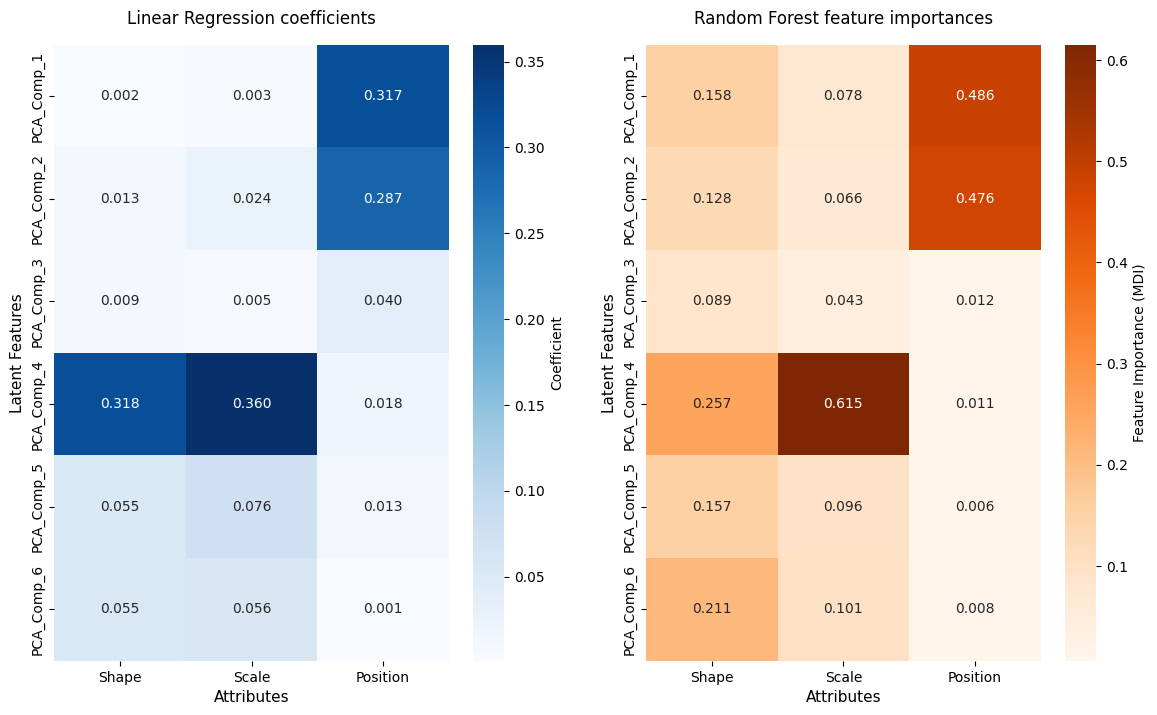

In [22]:
attributes = ['Shape', 'Scale', 'Position']

lr_cols = [f"{attr} (Linear Reg Coef)" for attr in attributes]
rf_cols = [f"{attr} (Random Forest Imp)" for attr in attributes]

lr_matrix = importance_df[lr_cols].values
rf_matrix = importance_df[rf_cols].values

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

sns.heatmap(
    lr_matrix, 
    annot=True, 
    fmt=".3f", 
    xticklabels=attributes, 
    yticklabels=feature_names, 
    cmap="Blues", 
    cbar_kws={'label': 'Coefficient'},
    ax=axes[0]
)
axes[0].set_title("Linear Regression coefficients", fontsize=12, pad=15)
axes[0].set_ylabel("Latent Features", fontsize=11)
axes[0].set_xlabel("Attributes", fontsize=11)

sns.heatmap(
    rf_matrix, 
    annot=True, 
    fmt=".3f", 
    xticklabels=attributes, 
    yticklabels=feature_names, 
    cmap="Oranges", 
    cbar_kws={'label': 'Feature Importance (MDI)'},
    ax=axes[1]
)
axes[1].set_title("Random Forest feature importances", fontsize=12, pad=15)
axes[1].set_ylabel("Latent Features", fontsize=11)
axes[1].set_xlabel("Attributes", fontsize=11)


                

## Kernel PCA

In [1]:
import sys
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import corner
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import StandardScaler

In [2]:
sys.path.append('/home/gandalf/objects')
from train_vae import BetaTCVAE

checkpoint_path = '/home/gandalf/objects/betatcvae_dim12_beta5.pth'
data_path = '/home/gandalf/objects/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
subsample_size = 10000  
batch_size = 256
n = 6


In [3]:
print(f"Loading checkpoint from {checkpoint_path}...")
checkpoint = torch.load(checkpoint_path, map_location=device)
checkpoint_args = checkpoint.get('args', {})
latent_dim = checkpoint_args.get('latent_dim', 12)

model = BetaTCVAE(latent_dim=latent_dim).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Model loaded. Latent dimension (k) = {latent_dim}")

Loading checkpoint from /home/gandalf/objects/betatcvae_dim12_beta5.pth...
Model loaded. Latent dimension (k) = 12


In [4]:
print("Loading dataset...")
data = np.load(data_path, allow_pickle=True, encoding='bytes')
imgs = data['imgs']

np.random.seed(42)
indices = np.random.choice(len(imgs), subsample_size, replace=False)
imgs_sub = imgs[indices]


Loading dataset...


In [5]:
mu_list = []
print("Encoding images into latent representations...")
with torch.no_grad():
    for i in range(0, len(imgs_sub), batch_size):
        batch_imgs = imgs_sub[i:i+batch_size]
        batch_tensor = torch.from_numpy(batch_imgs).float().unsqueeze(1).to(device)
        mu, _ = model.encode(batch_tensor)
        mu_list.append(mu.cpu().numpy())

mu_np = np.concatenate(mu_list, axis=0)
print(f"Extracted latents shape: {mu_np.shape}")


Encoding images into latent representations...
Extracted latents shape: (10000, 12)


In [6]:
scaler = StandardScaler()
mu_np= scaler.fit_transform(mu_np)

In [7]:
print(f"Computing Kernel PCA with RBF kernel (n_components={n})...")
kpca = KernelPCA(n_components=n, kernel='rbf', fit_inverse_transform=False, n_jobs=-1)
obtained_space = kpca.fit_transform(mu_np)
print(f"Kernel PCA completed. Shape: {obtained_space.shape}")


Computing Kernel PCA with RBF kernel (n_components=6)...
Kernel PCA completed. Shape: (10000, 6)


In [8]:
labels = [f"K-PCA Comp {i+1}" for i in range(n)]
title = f"Corner Plot of RBF Kernel PCA Space (n = {n} components)"


Generating corner plot...


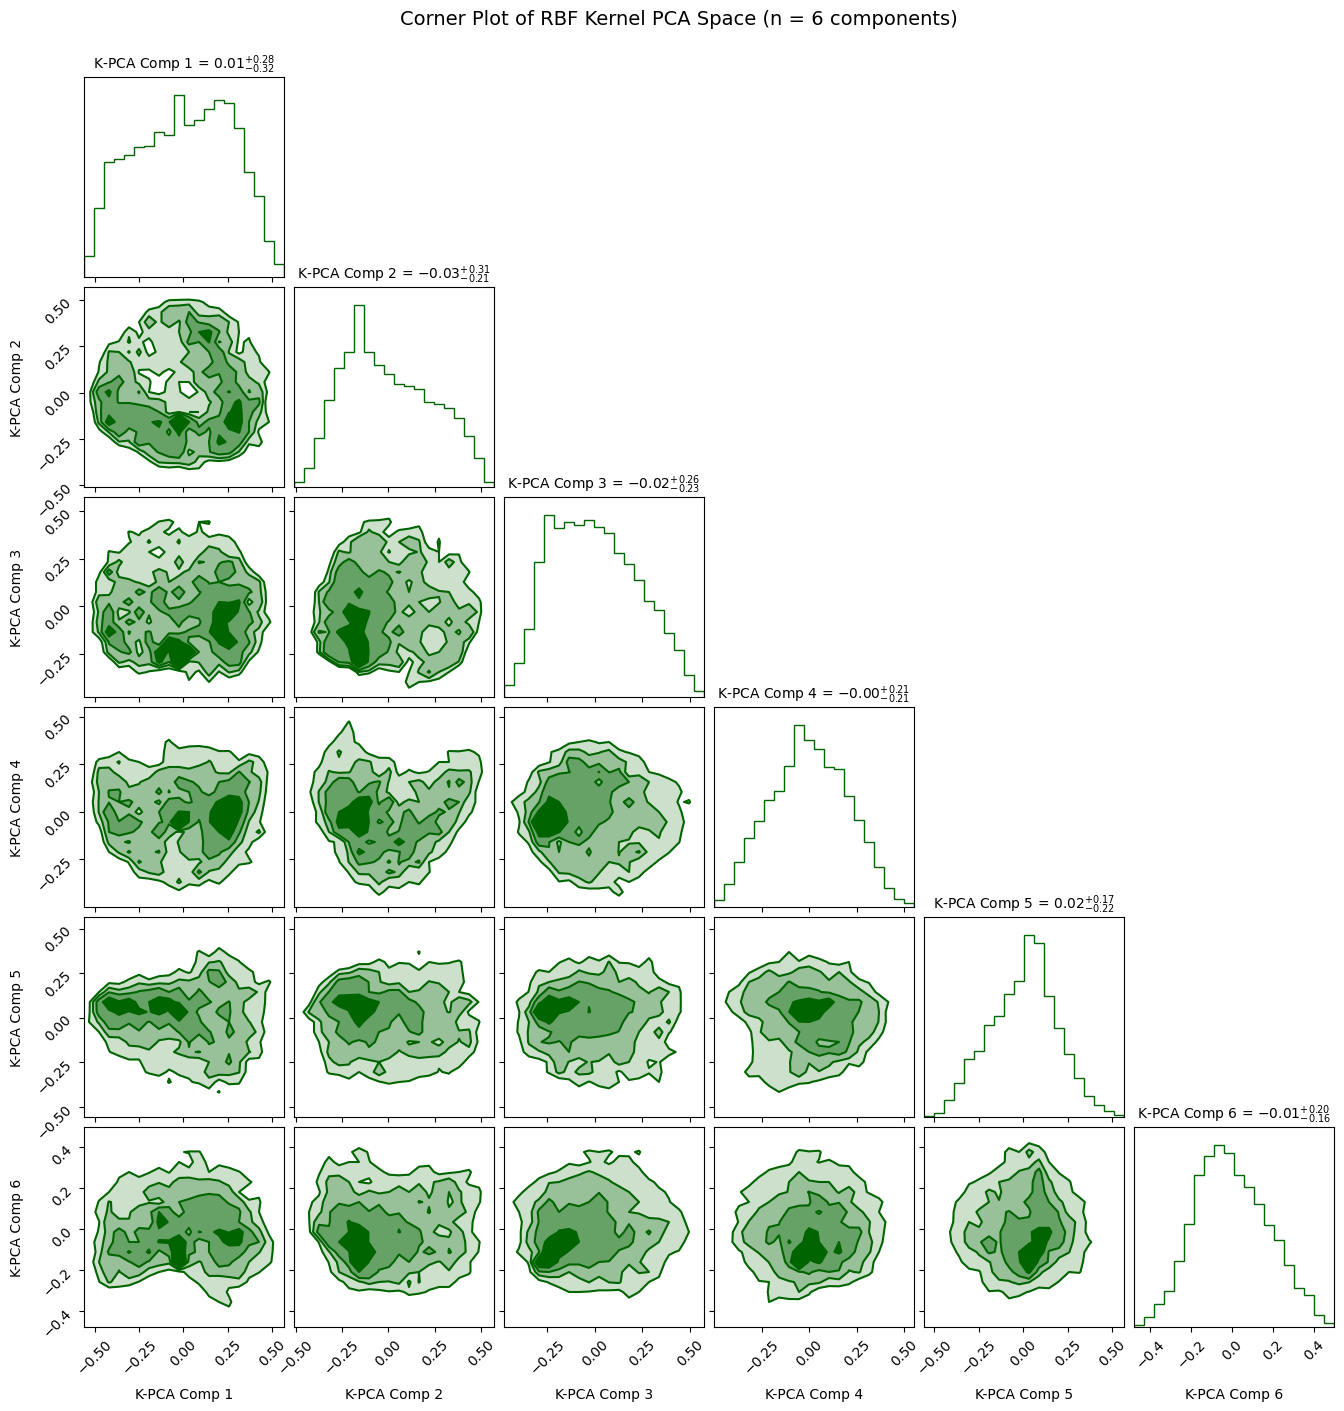

In [9]:

print("Generating corner plot...")
fig = corner.corner(
    obtained_space,
    labels=labels,
    show_titles=True,
    title_fmt=".2f",
    title_kwargs={"fontsize": 10},
    bins=20,
    plot_datapoints=False,
    plot_density=True,
    fill_contours=True,
    color="darkgreen"
)
fig.suptitle(title, y=1.02, fontsize=14)
plt.show()


In [10]:
torch.cuda.empty_cache()

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


In [1]:
import sys
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, accuracy_score

In [2]:

sys.path.append('/home/gandalf/objects')
from train_vae import BetaTCVAE

checkpoint_path = '/home/gandalf/objects/betatcvae_dim12_beta5.pth'
data_path = '/home/gandalf/objects/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
subsample_size = 15000  
batch_size = 256
n = 6                 

In [3]:

print(f"Loading checkpoint from {checkpoint_path}...")
checkpoint = torch.load(checkpoint_path, map_location=device)
checkpoint_args = checkpoint.get('args', {})
latent_dim = checkpoint_args.get('latent_dim', 12)

Loading checkpoint from /home/gandalf/objects/betatcvae_dim12_beta5.pth...


In [4]:


model = BetaTCVAE(latent_dim=latent_dim).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Model loaded. Latent dimension (k) = {latent_dim}")

print("Loading dataset...")
data = np.load(data_path, allow_pickle=True, encoding='bytes')
imgs = data['imgs']
latents_classes = data['latents_classes']

np.random.seed(42)
indices = np.random.choice(len(imgs), subsample_size, replace=False)
imgs_sub = imgs[indices]
latents_sub = latents_classes[indices]

shape_labels = latents_sub[:, 1]                            
scale_labels = (latents_sub[:, 2] >= 3).astype(np.int64)     
position_labels = (latents_sub[:, 4] >= 16).astype(np.int64) 

mu_list = []
print("Encoding images into latent representations...")
with torch.no_grad():
    for i in range(0, len(imgs_sub), batch_size):
        batch_imgs = imgs_sub[i:i+batch_size]
        batch_tensor = torch.from_numpy(batch_imgs).float().unsqueeze(1).to(device)
        mu, _ = model.encode(batch_tensor)
        mu_list.append(mu.cpu().numpy())

mu_np = np.concatenate(mu_list, axis=0)

scaler2= StandardScaler()
mu_nps= scaler2.fit_transform(mu_np)

print(f"Applying Kernel PCA with RBF kernel (n_components={n})...")
kpca = KernelPCA(n_components=n, kernel='rbf', fit_inverse_transform=False, n_jobs=-1)
X_features = kpca.fit_transform(mu_nps)
feature_names = [f"KPCA_Comp_{i+1}" for i in range(n)]

Model loaded. Latent dimension (k) = 12
Loading dataset...
Encoding images into latent representations...
Applying Kernel PCA with RBF kernel (n_components=6)...


Evaluating models for: Shape...
Evaluating models for: Scale...
Evaluating models for: Position...

=== Model Predictive Performance on KPCA Features ===


,Attribute,Linear Reg R2,Linear Reg Accuracy,Random Forest R2,Random Forest Accuracy
0,Shape,0.0633,0.3411,0.9488,0.9808
1,Scale,0.5581,0.8572,0.9615,0.9998
2,Position,0.7424,0.9748,0.9880,0.9999



=== KPCA Feature Importance Matrix ===


,Feature,Shape (Linear Reg Coef),Shape (Random Forest Imp),Scale (Linear Reg Coef),Scale (Random Forest Imp),Position (Linear Reg Coef),Position (Random Forest Imp)
0,KPCA_Comp_1,0.0343,0.1853,0.0206,0.0895,0.3753,0.6754
1,KPCA_Comp_2,0.0576,0.1593,0.1431,0.1613,0.1959,0.2014
2,KPCA_Comp_3,0.0668,0.1378,0.2454,0.2958,0.0297,0.0215
3,KPCA_Comp_4,0.1505,0.1234,0.2388,0.3036,0.0416,0.0336
4,KPCA_Comp_5,0.0441,0.2112,0.0338,0.0808,0.0444,0.0303
5,KPCA_Comp_6,0.0898,0.1831,0.0129,0.0691,0.0417,0.0377



Generating heatmaps...


Text(0.5, 58.7222222222222, 'Attributes')

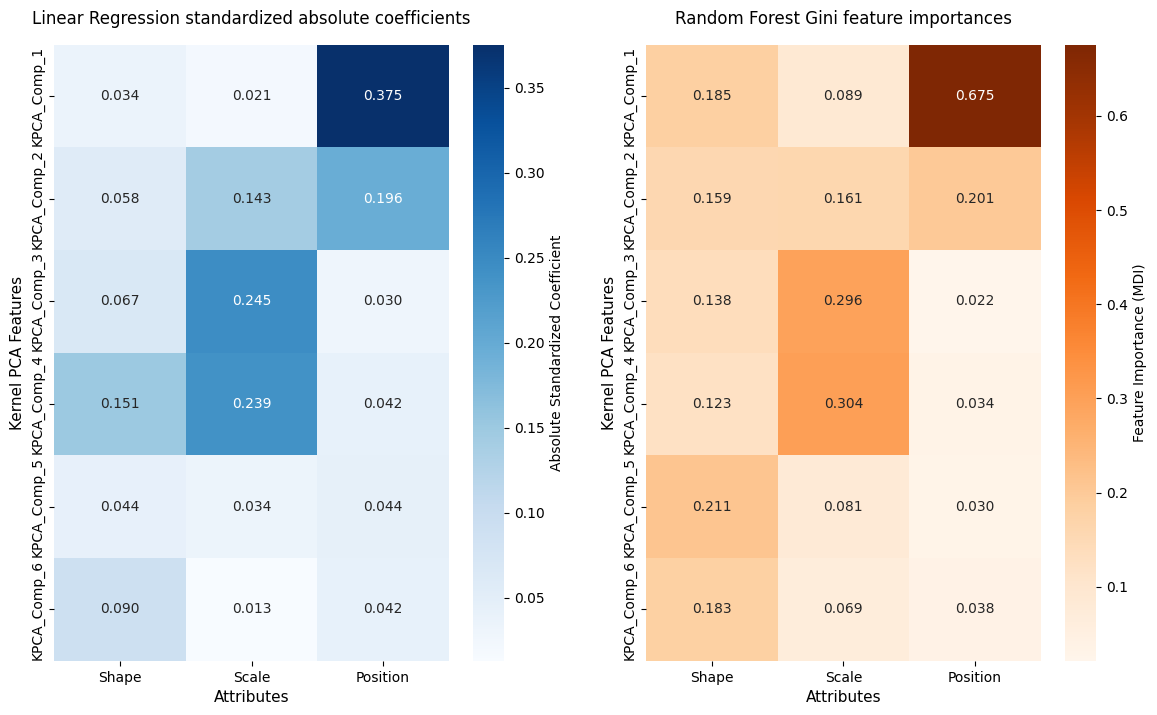

In [5]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

targets = {
    "Shape": shape_labels,
    "Scale": scale_labels,
    "Position": position_labels
}

importance_df = pd.DataFrame({"Feature": feature_names})
performance_records = []

for name, y in targets.items():
    print(f"Evaluating models for: {name}...")
    
    lr = LinearRegression()
    lr.fit(X_scaled, y)
    y_pred_lr = lr.predict(X_scaled)

    r2_lr = r2_score(y, y_pred_lr)
    y_pred_lr_rounded = np.clip(np.round(y_pred_lr), y.min(), y.max()).astype(int)
    acc_lr = accuracy_score(y, y_pred_lr_rounded)
    
 
    lr_importance = np.abs(lr.coef_)
    

    rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    rf.fit(X_features, y)
    y_pred_rf = rf.predict(X_features)
    
    r2_rf = r2_score(y, y_pred_rf)
    y_pred_rf_rounded = np.clip(np.round(y_pred_rf), y.min(), y.max()).astype(int)
    acc_rf = accuracy_score(y, y_pred_rf_rounded)
    
    rf_importance = rf.feature_importances_

    importance_df[f"{name} (Linear Reg Coef)"] = lr_importance
    importance_df[f"{name} (Random Forest Imp)"] = rf_importance
    
    performance_records.append({
        "Attribute": name,
        "Linear Reg R2": r2_lr,
        "Linear Reg Accuracy": acc_lr,
        "Random Forest R2": r2_rf,
        "Random Forest Accuracy": acc_rf
    })

performance_df = pd.DataFrame(performance_records)

print("\n=== Model Predictive Performance on KPCA Features ===")
display(performance_df.round(4))

print("\n=== KPCA Feature Importance Matrix ===")
display(importance_df.round(4))

print("\nGenerating heatmaps...")
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
attributes = list(targets.keys())

lr_cols = [f"{attr} (Linear Reg Coef)" for attr in attributes]
rf_cols = [f"{attr} (Random Forest Imp)" for attr in attributes]

lr_matrix = importance_df[lr_cols].values
rf_matrix = importance_df[rf_cols].values


sns.heatmap(
    lr_matrix, 
    annot=True, 
    fmt=".3f", 
    xticklabels=attributes, 
    yticklabels=feature_names, 
    cmap="Blues", 
    cbar_kws={'label': 'Absolute Standardized Coefficient'},
    ax=axes[0]
)
axes[0].set_title("Linear Regression standardized absolute coefficients", fontsize=12, pad=15)
axes[0].set_ylabel("Kernel PCA Features", fontsize=11)
axes[0].set_xlabel("Attributes", fontsize=11)

sns.heatmap(
    rf_matrix, 
    annot=True, 
    fmt=".3f", 
    xticklabels=attributes, 
    yticklabels=feature_names, 
    cmap="Oranges", 
    cbar_kws={'label': 'Feature Importance (MDI)'},
    ax=axes[1]
)
axes[1].set_title("Random Forest Gini feature importances", fontsize=12, pad=15)
axes[1].set_ylabel("Kernel PCA Features", fontsize=11)
axes[1].set_xlabel("Attributes", fontsize=11)


PCA Perturbation 

In [38]:
import os
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

In [39]:


sys.path.append('/home/gandalf/objects')
from train_vae import BetaTCVAE


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


In [40]:


checkpoint_path = '/home/gandalf/objects/betatcvae_dim12_beta5.pth'
data_path = '/home/gandalf/objects/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
subsample_size = 10000
batch_size = 256
n_pca_components = 6



In [41]:

print(f"Loading Beta-TCVAE checkpoint from {checkpoint_path}...")
checkpoint = torch.load(checkpoint_path, map_location=device)
checkpoint_args = checkpoint.get('args', {})
latent_dim = checkpoint_args.get('latent_dim', 12)

model = BetaTCVAE(latent_dim=latent_dim).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Model loaded successfully. VAE Latent dimension (k) = {latent_dim}")



Loading Beta-TCVAE checkpoint from /home/gandalf/objects/betatcvae_dim12_beta5.pth...
Model loaded successfully. VAE Latent dimension (k) = 12


In [42]:

print(f"Loading dSprites dataset from {data_path}...")
data = np.load(data_path, allow_pickle=True, encoding='bytes')
imgs = data['imgs']
latents_classes = data['latents_classes']

np.random.seed(42)
indices = np.random.choice(len(imgs), subsample_size, replace=False)
imgs_sub = imgs[indices]
latents_sub = latents_classes[indices]

shape_labels = latents_sub[:, 1]                             
scale_labels = (latents_sub[:, 2] >= 3).astype(np.int64)     
position_labels = (latents_sub[:, 4] >= 16).astype(np.int64)

targets_data = {
    "Shape": shape_labels,
    "Scale": scale_labels,
    "Position": position_labels
}


Loading dSprites dataset from /home/gandalf/objects/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz...


In [43]:

print("Encoding images to latent representations (mu)...")
mu_list = []
with torch.no_grad():
    for i in range(0, len(imgs_sub), batch_size):
        batch_imgs = imgs_sub[i:i+batch_size]
        batch_tensor = torch.from_numpy(batch_imgs).float().unsqueeze(1).to(device)
        mu, _ = model.encode(batch_tensor)
        mu_list.append(mu.cpu().numpy())

mu_np = np.concatenate(mu_list, axis=0)
print(f"Extracted latents mu_np shape: {mu_np.shape}")


Encoding images to latent representations (mu)...
Extracted latents mu_np shape: (10000, 12)


In [44]:

scaler = StandardScaler()
Z_scaled = scaler.fit_transform(mu_np)

pca = PCA(n_components=n_pca_components)
W_pca = pca.fit_transform(Z_scaled)  # W in 6D PCA coordinate space: (N, 6)

In [45]:

def pca_w_to_latent_z(w_vector, pca_model, scaler_model):
    
    w_2d = w_vector.reshape(1, -1) if w_vector.ndim == 1 else w_vector
    z_scaled_reconstructed = pca_model.inverse_transform(w_2d)
    z_reconstructed = scaler_model.inverse_transform(z_scaled_reconstructed)
    return z_reconstructed.squeeze(0) if w_vector.ndim == 1 else z_reconstructed


rf_classifiers = {}
rf_importances = {}

for attr_name, y_labels in targets_data.items():
    rf_clf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    rf_clf.fit(W_pca, y_labels)
    rf_classifiers[attr_name] = rf_clf
    rf_importances[attr_name] = rf_clf.feature_importances_

importance_df = pd.DataFrame(rf_importances, index=[f"PCA_{i}" for i in range(n_pca_components)])
print("\n=== Random Forest Feature Importances for 6D PCA Features ===")
display(importance_df.round(4))




=== Random Forest Feature Importances for 6D PCA Features ===


,Shape,Scale,Position
PCA_0,0.1587,0.1492,0.6750
PCA_1,0.1812,0.1772,0.1124
PCA_2,0.1573,0.2149,0.0918
PCA_3,0.1592,0.1864,0.0535
PCA_4,0.1780,0.1501,0.0284
PCA_5,0.1656,0.1223,0.0389


In [46]:

def get_user_specified_frozen_mask(importances, target_cumulative=0.75, max_factors=3):
    pca_dim = len(importances)
    mask = np.zeros(pca_dim, dtype=np.float32)
    
    total_imp = np.sum(importances)
    rel_importances = importances / (total_imp + 1e-8)
    sorted_indices = np.argsort(importances)[::-1]
    
    top_1_idx = sorted_indices[0]
    top_2_idx = sorted_indices[1] if pca_dim > 1 else sorted_indices[0]
    
    top_1_rel = rel_importances[top_1_idx]
    top_2_rel = rel_importances[top_2_idx]
    ratio_to_second = top_1_rel / (top_2_rel + 1e-8)
    
    if top_1_rel >= 0.50 or ratio_to_second >= 2.0:
        frozen_indices = [top_1_idx]
        reason = (f"Single top feature chosen: PCA_{top_1_idx} "
                  f"(Importance = {top_1_rel*100:.1f}%, Ratio to 2nd = {ratio_to_second:.2f}x)")
    else:
    
        selected = []
        cum_sum = 0.0
        for idx in sorted_indices:
            selected.append(idx)
            cum_sum += rel_importances[idx]
            if cum_sum >= target_cumulative or len(selected) >= max_factors:
                break
                
        frozen_indices = selected
        reason = (f"Multi-feature set chosen: {[f'PCA_{i}' for i in frozen_indices]} "
                  f"accounting for {cum_sum*100:.1f}% cumulative feature importance")
        
    mask[frozen_indices] = 1.0
    return mask, frozen_indices, reason




--- Row 1: Attribute 'Shape' ---
Mask Selection Decision: Multi-feature set chosen: ['PCA_1', 'PCA_4', 'PCA_5'] accounting for 52.5% cumulative feature importance
Mask Vector m (6D): [0. 1. 0. 0. 1. 1.]
Original Latent RF Class Prediction : Class 0 (Conf: 0.9400)
Step 1 (-2.0σ) RF Class Prediction : Class 2 (Conf: 0.6400)
Step 2 (-1.0σ) RF Class Prediction : Class 2 (Conf: 0.9200)
Step 3 (+1.0σ) RF Class Prediction : Class 1 (Conf: 0.4600)
Step 4 (+2.0σ) RF Class Prediction : Class 1 (Conf: 0.5600)

--- Row 2: Attribute 'Scale' ---
Mask Selection Decision: Multi-feature set chosen: ['PCA_2', 'PCA_3', 'PCA_1'] accounting for 57.9% cumulative feature importance
Mask Vector m (6D): [0. 1. 1. 1. 0. 0.]
Original Latent RF Class Prediction : Class 0 (Conf: 0.9000)
Step 1 (-2.0σ) RF Class Prediction : Class 0 (Conf: 0.5000)
Step 2 (-1.0σ) RF Class Prediction : Class 0 (Conf: 0.7400)
Step 3 (+1.0σ) RF Class Prediction : Class 0 (Conf: 0.8200)
Step 4 (+2.0σ) RF Class Prediction : Class 1 (Conf

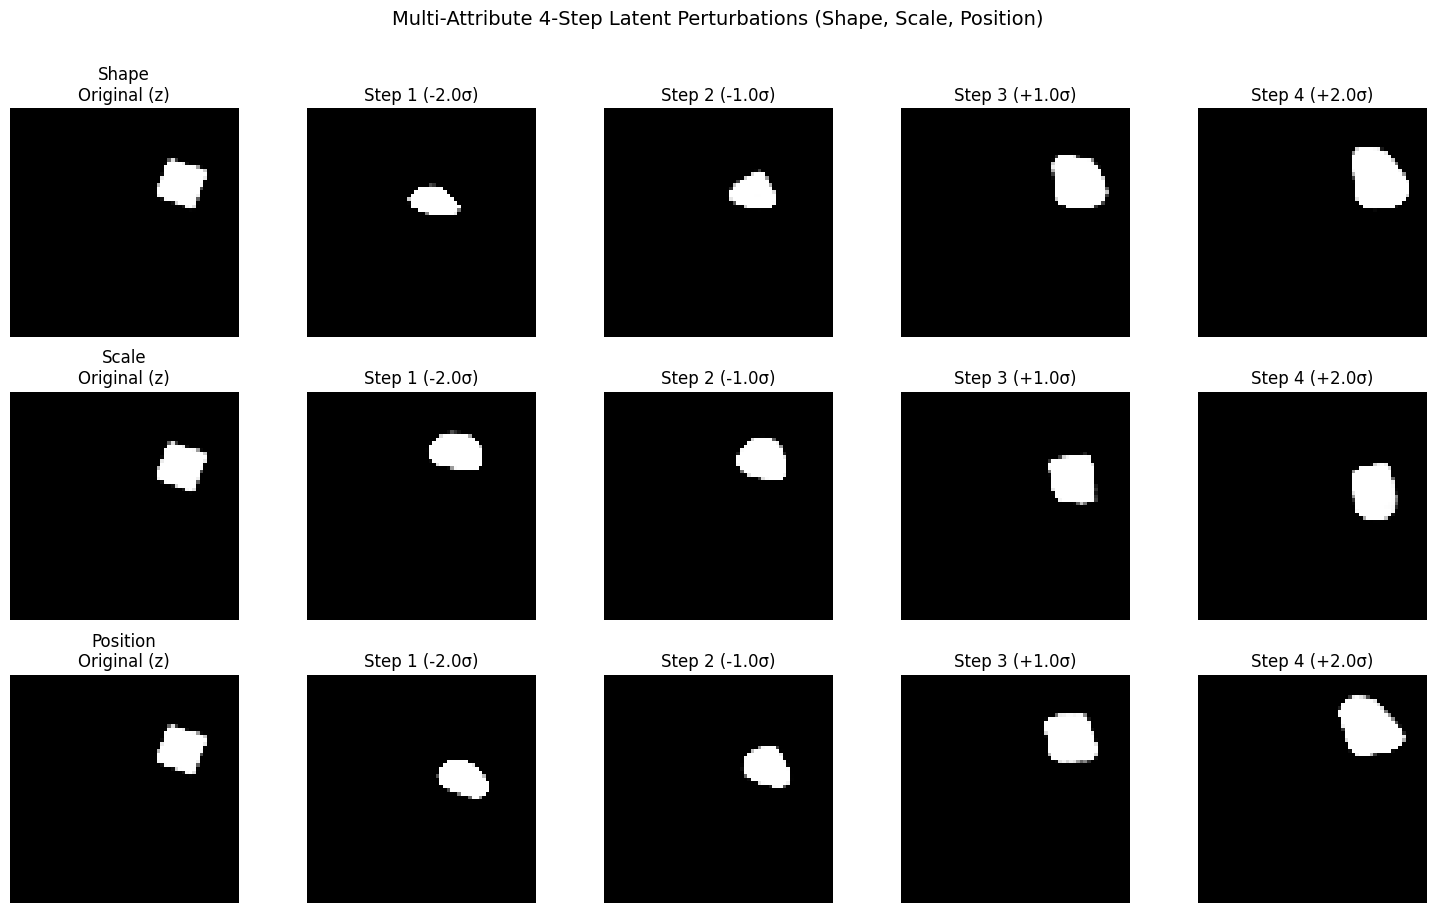

In [ ]:

target_idx = 0
z_target = mu_np[target_idx]

z_target_scaled = scaler.transform(z_target.reshape(1, -1))
w_target = pca.transform(z_target_scaled).squeeze(0)  # Shape: (6,)


steps_scale = [-2.0, -1.0, 1.0, 2.0]
num_steps = len(steps_scale)

pca_stds = np.sqrt(pca.explained_variance_)
np.random.seed(42)
base_delta = np.random.normal(loc=0.0, scale=1.0, size=n_pca_components).astype(np.float32) * pca_stds

z_target_tensor = torch.from_numpy(z_target).float().unsqueeze(0).to(device)
with torch.no_grad():
    orig_img = torch.sigmoid(model.decode(z_target_tensor))


num_attributes = len(targets_data)
fig, axes = plt.subplots(num_attributes, 5, figsize=(15, 3 * num_attributes))

for row_idx, (attr_name, y_labels) in enumerate(targets_data.items()):
    rf_clf = rf_classifiers[attr_name]
    importances = rf_importances[attr_name]
    mask, frozen_indices, selection_reason = get_user_specified_frozen_mask(importances, target_cumulative=0.75, max_factors=3)
    
    print(f"\n--- Row {row_idx+1}: Attribute '{attr_name}' ---")
    print(f"Mask Selection Decision: {selection_reason}")
    print(f"Mask Vector m (6D): {mask}")
  
    axes[row_idx, 0].imshow(orig_img.squeeze().cpu().numpy(), cmap='gray')
    axes[row_idx, 0].set_title(f"{attr_name}\nOriginal (z)")
    axes[row_idx, 0].axis('off')
    
    row_perturbed_imgs = []
    row_w_primes = []
    
    for i, scale_factor in enumerate(steps_scale):
        delta_s = scale_factor * base_delta
        w_prime = w_target + (1.0 - mask) * delta_s  
   
        z_prime = pca_w_to_latent_z(w_prime, pca, scaler)
    
        z_prime_tensor = torch.from_numpy(z_prime).float().unsqueeze(0).to(device)
        with torch.no_grad():
            recon_img = torch.sigmoid(model.decode(z_prime_tensor))
            
        row_perturbed_imgs.append(recon_img)
        row_w_primes.append(w_prime)
        
        axes[row_idx, i+1].imshow(recon_img.squeeze().cpu().numpy(), cmap='gray')
        axes[row_idx, i+1].set_title(f"Step {i+1} ({scale_factor:+0.1f}\u03c3)")
        axes[row_idx, i+1].axis('off')
        
    orig_pred_class = rf_clf.predict(w_target.reshape(1, -1))[0]
    orig_pred_prob = np.max(rf_clf.predict_proba(w_target.reshape(1, -1))[0])
    print(f"Original Latent RF Class Prediction : Class {orig_pred_class} (Conf: {orig_pred_prob:.4f})")
    
    for i, w_p in enumerate(row_w_primes):
        step_pred_class = rf_clf.predict(w_p.reshape(1, -1))[0]
        step_pred_prob = np.max(rf_clf.predict_proba(w_p.reshape(1, -1))[0])
        print(f"Step {i+1} ({steps_scale[i]:+0.1f}\u03c3) RF Class Prediction : Class {step_pred_class} (Conf: {step_pred_prob:.4f})")

plt.suptitle("Multi-Attribute 4-Step Latent Perturbations (Shape, Scale, Position)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()
